# Урок 17. Когда одного пятна мало

[План курса](../../README_ru.md)

На образце две синие бусины со светлым промежутком. У модели вместо них одно широкое пятно и почти прозрачная крошка в стороне. Широкое пятно можно передвигать и ослаблять. Но у его горизонтального среза одна вершина, а у образца две. Иногда следующим шагом становится изменение самого списка гауссиан.

In [1]:
%matplotlib inline
from pathlib import Path
import sys
course_root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'splat_render.py').is_file())
if str(course_root) not in sys.path:
    sys.path.insert(0, str(course_root))
import numpy as np
from IPython.display import display
import matplotlib.pyplot as plt
import splat_render as sr
import splat_demos as demo

## Один старт, несколько продолжений

Камера, цвет и фон закреплены. Слева образец, справа модель. Отдельные действия дают клон выбранного пятна, заменяют его двумя дочерними, убирают слабые пятна или уменьшают непрозрачность всех сразу. По очереди можно сравнить эти действия из одной исходной сцены. Обычный шаг градиента двигает центры по горизонтали и меняет непрозрачность.

У каждого сравнения есть три разных числа. MSE говорит о цвете 33 × 33 пикселей. Число пятен — о длине списка. Размер в байтах учитывает только сохранённые числовые параметры в формате float32. Если действие получилось дорогим и ухудшило картинку, это тоже результат опыта.

In [2]:
display(demo.experiment(17, "ru"))

## Шаг внутри списка

Сначала в списке два пятна. У большого $x=-0.16$, горизонтальная ширина $s_x=0.63$, центральная непрозрачность $o=0.77$. Сдвиг на малое расстояние меняет RGB кадра и его ошибку. Для двух производных делаем по два замера из одного и того же исходного состояния, как в прошлом уроке. Получаем $g_x\approx-0.00304635$ единицы MSE на единицу длины и $g_o\approx0.00834045$ на единицу непрозрачности.

При размере шага $\eta=3$ новая координата $x'=-0.16-3(-0.00304635)\approx-0.15086$. Новая непрозрачность $o'=0.77-3(0.00834045)\approx0.74498$. Сдвиг получается вправо, пятно чуть светлеет на белом фоне. Шаг для маленького пятна считается по его собственным двум производным. После одновременного обновления MSE уменьшается с $0.00467723$ до $0.00446188$. Индексы 0 и 1 по-прежнему указывают на те же два пятна. Градиент числа с индексом 0 не создаёт строку с индексом 2.

In [3]:
initial = sr.density_scene()
print(np.round(sr.density_gradients(initial), 7))
updated = sr.density_step(initial)
print(updated["splats"][0]["center"], updated["splats"][0]["opacity"])
assert len(initial["splats"]) == len(updated["splats"]) == 2
assert sr.density_loss(updated) < sr.density_loss(initial)

[[-3.0463e-03  8.3405e-03]
 [ 4.5300e-05 -5.5900e-05]]
[-0.1508609595795733, 0, 4] 0.7449786379339152


## Клон затемняет, разделение меняет форму

**Клон** добавляет в конец копию центра, формы, цвета и непрозрачности. В центре исходного пятна $\alpha=0.77$, оно пропускало $1-0.77=0.23$ света фона. Два одинаковых слоя пропускают $0.23\cdot0.23=0.0529$, суммарная непрозрачность $1-0.0529=0.9471$. Поэтому одинаковые координаты не означают ту же картинку. Слишком тёмная синяя область увеличивает MSE до $0.01214659$. Дальше параметры двух копий можно менять независимо.

**Разделение** удаляет широкого родителя, а взамен добавляет двух детей. Чтобы опыт повторялся, положим их симметрично по горизонтали. Сначала считаем смещение $0.65\cdot0.63=0.4095$, затем центры $-0.16-0.4095=-0.5695$ и $-0.16+0.4095=0.2495$. Все три масштаба делим на $1.6$. Например, горизонтальный $0.63/1.6=0.39375$. Цвет и $o$ дети получают от родителя. Две вершины уже угадываются, а MSE становится $0.00347211$. При другом образце или другом исходном пятне такое деление способно ухудшить изображение.

И клон, и разделение увеличили список с двух строк до трёх. В первом случае в списке остаются родитель и его копия. Во втором родителя больше нет, есть два смещённых пятна и прежняя крошка.

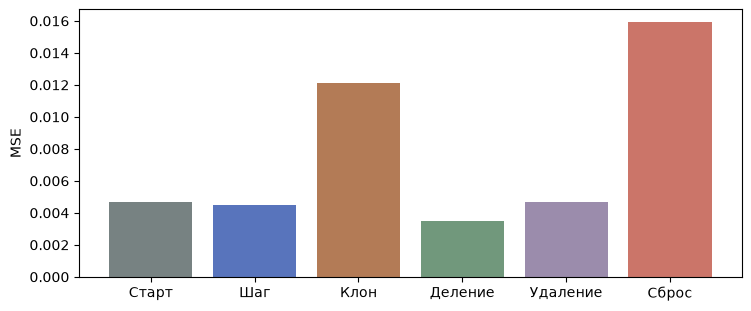

In [4]:
fig = demo.density_chart("ru")
display(fig)
plt.close(fig)

## Удаление и сброс — две разные истории

**Удаление, или pruning**, вычёркивает пятно целиком. Наш порог $0.03$ относится к непрозрачности в центре. У крошки $o=0.015<0.03$, поэтому она исчезает. От большого пятна отказываться рано. Список становится короче, а ошибка почти та же, $0.00467882$. Она слегка **выросла**. Маленькое влияние и нулевое влияние — разные вещи.

**Сброс непрозрачности** оставляет центры и формы на местах. Новое значение $o'=\min(o,0.01)$ означает меньшее из прежнего $o$ и одной сотой. Например, $0.77$ станет $0.01$, а $0.004$ останется $0.004$. Пока пятна слабы, через них проходит больше света и вклад скрытого слоя может стать видимее. Оптимизация заново наращивает полезные непрозрачности. Непосредственно после сброса картинка почти белая, MSE $0.01592582$. Если тут же применить порог удаления $0.03$, не останется ни одного пятна. В полном обучении важны порядок и расписание операций.

In [5]:
for action in ("clone","split","prune","reset"):
    scene = sr.density_edit(initial, action)
    n = len(scene["splats"])
    print(f"{action:6s} N={n}, bytes={56*n}, MSE={sr.density_loss(scene):.8f}")
assert len(sr.density_edit(sr.density_edit(initial, "reset"), "prune")["splats"]) == 0

clone  N=3, bytes=168, MSE=0.01214659
split  N=3, bytes=168, MSE=0.00347211
prune  N=1, bytes=56, MSE=0.00467882
reset  N=2, bytes=112, MSE=0.01592582


## Как решение принимает программа

В одном автоматическом проходе опыта сначала считаем все градиенты в прежней сцене. Для каждого пятна с $o<0.03$ выбираем удаление. У остальных сравниваем модуль горизонтального градиента с порогом $0.001$. Для большого пятна $|-0.00304635|>0.001$. Так программа замечает участок, где движение центра может заметно изменить ошибку. Это чувствительность к сдвигу, а не гарантия, что именно там лежит недостающая деталь.

Теперь нужен выбор между копией и двумя детьми. В этом опыте горизонтальный масштаб больше $0.32$ означает широкое пятно. При $0.63>0.32$ выбирается деление. Для достаточно узкого пятна с таким же сильным сигналом выбирался бы клон. Запас ограничен 16 пятнами, чтобы каждый шаг удобно разбирать. После первого автоматического прохода широкое пятно заменено двумя, слабое удалено, общее число снова равно двум. MSE уже другая, около $0.00348773$. Одного счётчика недостаточно, чтобы заметить перестройку сцены.

У авторов 3DGS сигнал копится для **видимых** пятен по нескольким шагам. Берутся длины двумерных градиентов по экранному центру и усредняются по наблюдениям. Размер сравнивается с масштабом сцены. При разделении положение детей случайно выбирается относительно формы и ориентации родителя. Код также умеет удалять чрезмерно крупные следы. Наша однокамерная версия использует производную по мировой $x$, фиксированное смещение детей и явные кнопки. Численные пороги из этого примера относятся только к его координатам и loss. [Алгоритм в статье](https://repo-sam.inria.fr/fungraph/3d-gaussian-splatting/) и [операции над параметрами в исходниках](https://github.com/graphdeco-inria/gaussian-splatting/blob/main/scene/gaussian_model.py).

In [6]:
adaptive = sr.density_pass(initial)
print([(s["center"][0],s["scales"][0],s["opacity"]) for s in adaptive["splats"]])
assert len(adaptive["splats"]) == len(initial["splats"])
assert sr.density_loss(adaptive) < sr.density_loss(initial)
for _ in range(8):
    adaptive = sr.density_step(adaptive)
print("8 steps:", sr.density_loss(adaptive))

[(-0.5695, 0.39375, 0.77), (0.24950000000000003, 0.39375, 0.77)]


8 steps: 0.0028990938514448354


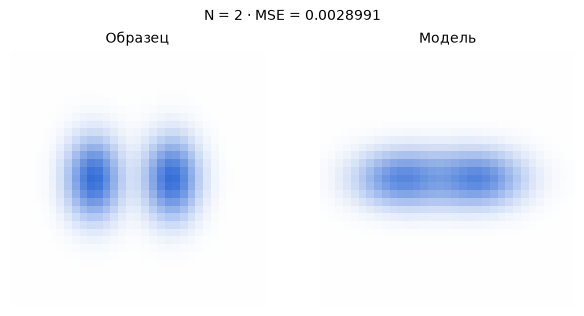

In [7]:
fig = demo.density_figure("ru", operation="adaptive", steps=8)
display(fig)
plt.close(fig)

## Опыты и разбор

Сколько памяти прибавил один клон? Почему итоговую разницу в занятой памяти видеокарты нельзя получить из одного этого числа?

<details><summary>Разбор</summary>

У пятна три координаты, три масштаба, четыре компоненты кватерниона, три цвета и одна непрозрачность. Всего $3+3+4+3+1=14$ чисел. В float32 одно число занимает $32/8=4$ байта. Один клон добавил $14\cdot4=56$ байт полезных параметров. При двух пятнах это 112 байт, при трёх 168. У полноценной модели появляются коэффициенты SH, градиенты, состояние оптимизатора, списки тайлов и временные изображения. Текстовый JSON тоже хранит символы и ключи. Здесь измеряется ровно числовая часть выбранного представления.

</details>